In [ ]:
import numpy as np
import matplotlib.pyplot as plt

column_types = [
    ("rownames", int),
    ("family", "U10"),
    ("father", float),
    ("mother", float),
    ("midparentHeight", float),
    ("children", int),
    ("childNum", int),
    ("gender", "U10"),
    ("childHeight", float),
]

# Load the dataset (skip the header row since we named the columns ourselves)
data = np.genfromtxt(
    "GaltonFamilies.csv",
    delimiter=",",
    skip_header=1,
    dtype=column_types,
    encoding="utf-8"
)

# Display the first five rows
print(data[:5])

# Extract one mother per family, and all children
_, unique_indices = np.unique(data["family"], return_index=True)

mothers = data["mother"][unique_indices]
children = data["childHeight"]

# Combine the heights without labels
heights = np.concatenate((mothers, children))

print("Number of mothers:", len(mothers))
print("Number of children:", len(children))
print("Total observations:", len(heights))
print("Overall mean:", np.mean(heights))

[(1, '001', 78.5, 67. , 75.43, 4, 1, 'male', 73.2)
 (2, '001', 78.5, 67. , 75.43, 4, 2, 'female', 69.2)
 (3, '001', 78.5, 67. , 75.43, 4, 3, 'female', 69. )
 (4, '001', 78.5, 67. , 75.43, 4, 4, 'female', 69. )
 (5, '002', 75.5, 66.5, 73.66, 4, 1, 'male', 73.5)]
Number of mothers: 205
Number of children: 934
Total observations: 1139
Overall mean: 66.25206321334504


In [5]:

# Extract unique mothers using family IDs
_, indices = np.unique(data["family"], return_index=True)

mothers = data["mother"][indices]

# Extract children's heights
children = data["childHeight"]

# Check the number of observations
print("Number of mothers:", len(mothers))
print("Number of children:", len(children))


Number of mothers: 205
Number of children: 934


In [6]:
# Combine mothers' and children's heights
heights = np.concatenate((mothers, children))

print("Total observations:", len(heights))
print("Overall mean:", np.mean(heights))
print("Overall variance:", np.var(heights))
print("Minimum height:", np.min(heights))
print("Maximum height:", np.max(heights))


Total observations: 1139
Overall mean: 66.25206321334504
Overall variance: 12.580160361236732
Minimum height: 56.0
Maximum height: 79.0


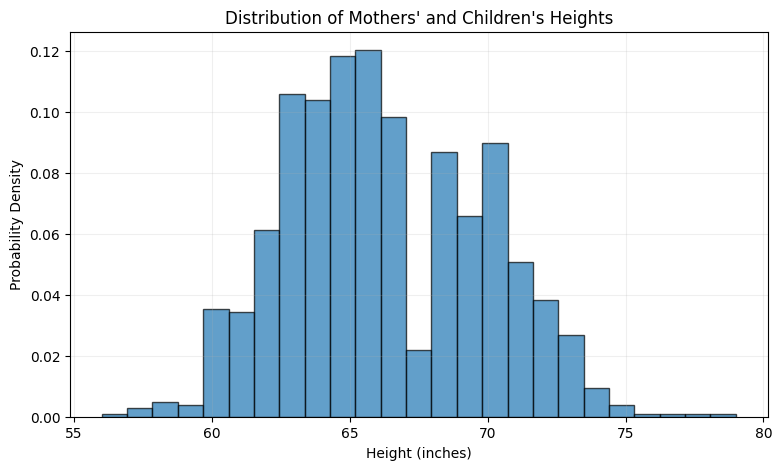

In [7]:
plt.figure(figsize=(9, 5))

plt.hist(
    heights,
    bins=25,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Height (inches)")
plt.ylabel("Probability Density")
plt.title("Distribution of Mothers' and Children's Heights")
plt.grid(alpha=0.2)

plt.show()


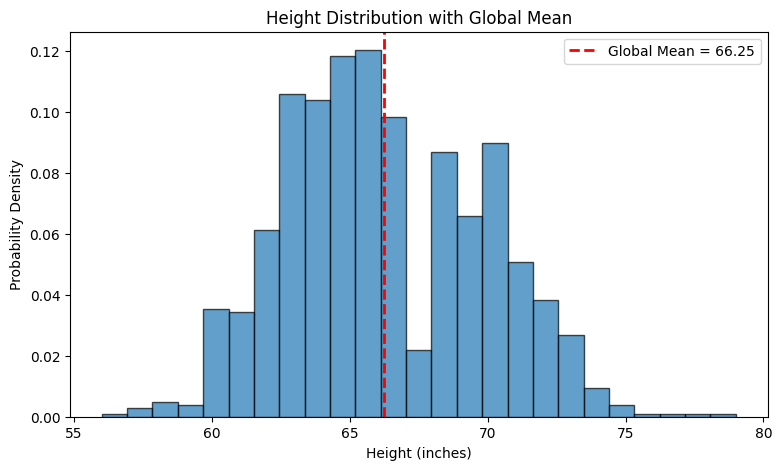

In [8]:
global_mean = np.mean(heights)

plt.figure(figsize=(9, 5))

plt.hist(
    heights,
    bins=25,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    global_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Global Mean = {global_mean:.2f}"
)

plt.xlabel("Height (inches)")
plt.ylabel("Probability Density")
plt.title("Height Distribution with Global Mean")
plt.legend()
plt.show()


In [9]:
# Initialize the means
mean1 = np.percentile(heights, 60)
mean2 = np.percentile(heights, 70)

# Initialize the variances
var1 = np.var(heights)
var2 = np.var(heights)

# Initialize the mixing weights
pi1 = 0.5
pi2 = 0.5

# Display the initial parameters
print("Initial mean 1:", mean1)
print("Initial mean 2:", mean2)
print("Initial variance 1:", var1)
print("Initial variance 2:", var2)
print("Initial pi1:", pi1)
print("Initial pi2:", pi2)


Initial mean 1: 67.0
Initial mean 2: 68.0
Initial variance 1: 12.580160361236732
Initial variance 2: 12.580160361236732
Initial pi1: 0.5
Initial pi2: 0.5
